In [1]:
import os
import zipfile
import urllib.request

# Create dataset directory
os.makedirs("/content/ars_data", exist_ok=True)

# Official UCI download
url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

zip_path = "/content/ars_data/uci_har.zip"

print("Downloading UCI HAR dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download completed!")

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Checking archive...")
    assert zip_ref.testzip() is None, "ZIP archive is corrupted!"

    zip_ref.extractall("/content/ars_data")

print("Extraction completed!")

Download completed!
Checking archive...
Extraction completed!


In [2]:
import os

dataset_path = "/content/ars_data/UCI HAR Dataset"

print("Dataset exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        continue

    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

Dataset exists: False


In [3]:
import os

print("Contents of ars_data:")

if os.path.exists("/content/ars_data"):
    print(os.listdir("/content/ars_data"))
else:
    print("ars_data folder does not exist")

Contents of ars_data:
['uci_har.zip', 'UCI HAR Dataset.zip', 'UCI HAR Dataset.names']


In [5]:
import zipfile
import os

for filename in ["uci_har.zip", "UCI HAR Dataset.zip"]:
    path = f"/content/ars_data/{filename}"
    print(f"\n--- {filename} ---")

    with zipfile.ZipFile(path, "r") as z:
        print("ZIP valid:", z.testzip() is None)
        print("First 10 entries:")
        for name in z.namelist()[:10]:
            print(" ", name)


--- uci_har.zip ---
ZIP valid: True
First 10 entries:
  UCI HAR Dataset.names
  UCI HAR Dataset.zip

--- UCI HAR Dataset.zip ---
ZIP valid: True
First 10 entries:
  UCI HAR Dataset/
  UCI HAR Dataset/.DS_Store
  __MACOSX/
  __MACOSX/UCI HAR Dataset/
  __MACOSX/UCI HAR Dataset/._.DS_Store
  UCI HAR Dataset/activity_labels.txt
  __MACOSX/UCI HAR Dataset/._activity_labels.txt
  UCI HAR Dataset/features.txt
  __MACOSX/UCI HAR Dataset/._features.txt
  UCI HAR Dataset/features_info.txt


In [6]:
import zipfile
import os

zip_path = "/content/ars_data/UCI HAR Dataset.zip"
extract_path = "/content/ars_data"

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

dataset_path = "/content/ars_data/UCI HAR Dataset"

print("\nDataset extracted:", os.path.exists(dataset_path))
print("Dataset folders:", os.listdir(dataset_path))

Extracting dataset...

Dataset extracted: True
Dataset folders: ['test', 'features.txt', 'README.txt', 'activity_labels.txt', 'train', 'features_info.txt', '.DS_Store']


In [7]:
import os

dataset_path = "/content/ars_data/UCI HAR Dataset"

for folder in ["train", "test"]:
    folder_path = os.path.join(dataset_path, folder)

    print(f"\n{'='*35}")
    print(f"{folder.upper()} DATA")
    print(f"{'='*35}")

    for root, dirs, files in os.walk(folder_path):
        level = root.replace(folder_path, "").count(os.sep)

        if level > 1:
            continue

        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in sorted(files):
            print(f"{indent}    {file}")


TRAIN DATA
train/
    X_train.txt
    subject_train.txt
    y_train.txt
    Inertial Signals/
        body_acc_x_train.txt
        body_acc_y_train.txt
        body_acc_z_train.txt
        body_gyro_x_train.txt
        body_gyro_y_train.txt
        body_gyro_z_train.txt
        total_acc_x_train.txt
        total_acc_y_train.txt
        total_acc_z_train.txt

TEST DATA
test/
    X_test.txt
    subject_test.txt
    y_test.txt
    Inertial Signals/
        body_acc_x_test.txt
        body_acc_y_test.txt
        body_acc_z_test.txt
        body_gyro_x_test.txt
        body_gyro_y_test.txt
        body_gyro_z_test.txt
        total_acc_x_test.txt
        total_acc_y_test.txt
        total_acc_z_test.txt


In [8]:
import numpy as np
import os

base = "/content/ars_data/UCI HAR Dataset"

# Load labels and participant IDs
y_train = np.loadtxt(f"{base}/train/y_train.txt", dtype=int)
y_test = np.loadtxt(f"{base}/test/y_test.txt", dtype=int)

subjects_train = np.loadtxt(
    f"{base}/train/subject_train.txt", dtype=int
)
subjects_test = np.loadtxt(
    f"{base}/test/subject_test.txt", dtype=int
)

# Inspect feature dimensions
X_train = np.loadtxt(f"{base}/train/X_train.txt")
X_test = np.loadtxt(f"{base}/test/X_test.txt")

# Inspect one raw sensor signal
signal = np.loadtxt(
    f"{base}/train/Inertial Signals/body_acc_x_train.txt"
)

print("TRAINING DATA")
print("Feature matrix:", X_train.shape)
print("Labels:", y_train.shape)
print("Participants:", subjects_train.shape)
print("One raw sensor signal:", signal.shape)

print("\nTEST DATA")
print("Feature matrix:", X_test.shape)
print("Labels:", y_test.shape)
print("Participants:", subjects_test.shape)

print("\nACTIVITY LABELS")
print("Training:", np.unique(y_train))
print("Testing:", np.unique(y_test))

print("\nPARTICIPANTS")
print("Training participants:", np.unique(subjects_train))
print("Testing participants:", np.unique(subjects_test))

overlap = set(subjects_train) & set(subjects_test)
print("Participants appearing in both:", overlap)

TRAINING DATA
Feature matrix: (7352, 561)
Labels: (7352,)
Participants: (7352,)
One raw sensor signal: (7352, 128)

TEST DATA
Feature matrix: (2947, 561)
Labels: (2947,)
Participants: (2947,)

ACTIVITY LABELS
Training: [1 2 3 4 5 6]
Testing: [1 2 3 4 5 6]

PARTICIPANTS
Training participants: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Testing participants: [ 2  4  9 10 12 13 18 20 24]
Participants appearing in both: set()


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "/content/ars_data/UCI HAR Dataset"

# Load activity names
activity_labels = pd.read_csv(
    f"{dataset_path}/activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# Load training and testing labels
y_train = pd.read_csv(
    f"{dataset_path}/train/y_train.txt",
    header=None, names=["activity_id"]
)

y_test = pd.read_csv(
    f"{dataset_path}/test/y_test.txt",
    header=None, names=["activity_id"]
)

# Convert numeric labels into activity names
label_map = dict(zip(
    activity_labels["activity_id"],
    activity_labels["activity_name"]
))

y_train["activity"] = y_train["activity_id"].map(label_map)
y_test["activity"] = y_test["activity_id"].map(label_map)

print("Activity mapping:")
print(activity_labels.to_string(index=False))

print("\nTraining activity distribution:")
print(y_train["activity"].value_counts().sort_index())

print("\nTesting activity distribution:")
print(y_test["activity"].value_counts().sort_index())

Activity mapping:
 activity_id      activity_name
           1            WALKING
           2   WALKING_UPSTAIRS
           3 WALKING_DOWNSTAIRS
           4            SITTING
           5           STANDING
           6             LAYING

Training activity distribution:
activity
LAYING                1407
SITTING               1286
STANDING              1374
WALKING               1226
WALKING_DOWNSTAIRS     986
WALKING_UPSTAIRS      1073
Name: count, dtype: int64

Testing activity distribution:
activity
LAYING                537
SITTING               491
STANDING              532
WALKING               496
WALKING_DOWNSTAIRS    420
WALKING_UPSTAIRS      471
Name: count, dtype: int64


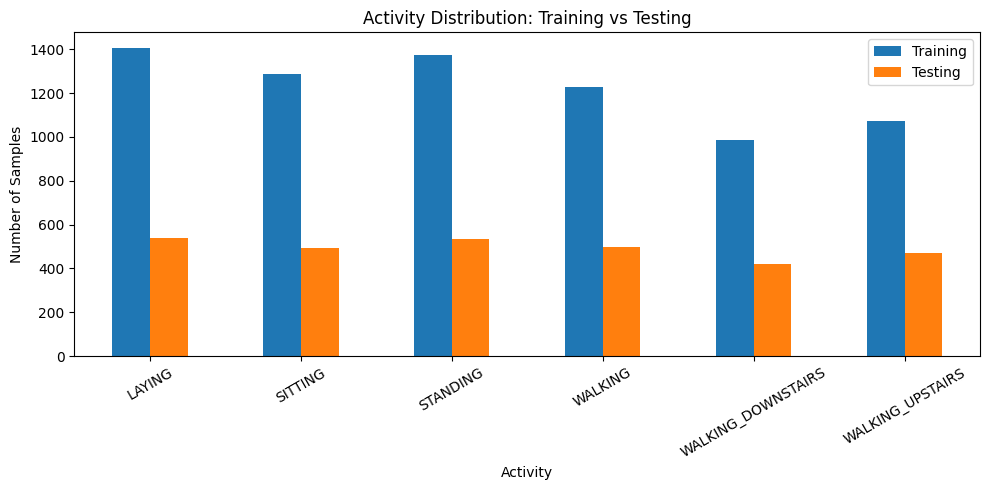

In [10]:
train_counts = y_train["activity"].value_counts().sort_index()
test_counts = y_test["activity"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Training": train_counts,
    "Testing": test_counts
})

distribution.plot(kind="bar", figsize=(10, 5))

plt.title("Activity Distribution: Training vs Testing")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

dataset_path = "/content/ars_data/UCI HAR Dataset"

features = pd.read_csv(
    f"{dataset_path}/features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"]
)

print("Total features:", len(features))

print("\nFirst 20 features:")
print(features.head(20).to_string(index=False))

print("\nLast 10 features:")
print(features.tail(10).to_string(index=False))

print("\nDuplicate feature names:",
      features["feature_name"].duplicated().sum())

print("\nMissing feature names:",
      features["feature_name"].isna().sum())

Total features: 561

First 20 features:
 feature_id        feature_name
          1   tBodyAcc-mean()-X
          2   tBodyAcc-mean()-Y
          3   tBodyAcc-mean()-Z
          4    tBodyAcc-std()-X
          5    tBodyAcc-std()-Y
          6    tBodyAcc-std()-Z
          7    tBodyAcc-mad()-X
          8    tBodyAcc-mad()-Y
          9    tBodyAcc-mad()-Z
         10    tBodyAcc-max()-X
         11    tBodyAcc-max()-Y
         12    tBodyAcc-max()-Z
         13    tBodyAcc-min()-X
         14    tBodyAcc-min()-Y
         15    tBodyAcc-min()-Z
         16      tBodyAcc-sma()
         17 tBodyAcc-energy()-X
         18 tBodyAcc-energy()-Y
         19 tBodyAcc-energy()-Z
         20    tBodyAcc-iqr()-X

Last 10 features:
 feature_id                         feature_name
        552      fBodyBodyGyroJerkMag-meanFreq()
        553      fBodyBodyGyroJerkMag-skewness()
        554      fBodyBodyGyroJerkMag-kurtosis()
        555          angle(tBodyAccMean,gravity)
        556 angle(tBodyA

In [12]:
# Find duplicated feature names
duplicates = features[
    features["feature_name"].duplicated(keep=False)
].sort_values("feature_name")

print("Number of rows involved in duplicate names:",
      len(duplicates))

print("\nFirst 30 duplicate entries:")
print(duplicates.head(30).to_string(index=False))

print("\nMost frequently duplicated names:")
print(
    features["feature_name"]
    .value_counts()
    .loc[lambda x: x > 1]
    .head(20)
)

Number of rows involved in duplicate names: 126

First 30 duplicate entries:
 feature_id                 feature_name
        339  fBodyAcc-bandsEnergy()-1,16
        325  fBodyAcc-bandsEnergy()-1,16
        311  fBodyAcc-bandsEnergy()-1,16
        343  fBodyAcc-bandsEnergy()-1,24
        329  fBodyAcc-bandsEnergy()-1,24
        315  fBodyAcc-bandsEnergy()-1,24
        331   fBodyAcc-bandsEnergy()-1,8
        317   fBodyAcc-bandsEnergy()-1,8
        303   fBodyAcc-bandsEnergy()-1,8
        333 fBodyAcc-bandsEnergy()-17,24
        305 fBodyAcc-bandsEnergy()-17,24
        319 fBodyAcc-bandsEnergy()-17,24
        312 fBodyAcc-bandsEnergy()-17,32
        340 fBodyAcc-bandsEnergy()-17,32
        326 fBodyAcc-bandsEnergy()-17,32
        306 fBodyAcc-bandsEnergy()-25,32
        334 fBodyAcc-bandsEnergy()-25,32
        320 fBodyAcc-bandsEnergy()-25,32
        330 fBodyAcc-bandsEnergy()-25,48
        344 fBodyAcc-bandsEnergy()-25,48
        316 fBodyAcc-bandsEnergy()-25,48
        307 fBodyAcc-

In [13]:
import numpy as np

X_train = pd.read_csv(
    f"{dataset_path}/train/X_train.txt",
    sep=r"\s+",
    header=None
)

print("Shape:", X_train.shape)

print("Missing values:", X_train.isna().sum().sum())

print("Infinite values:", np.isinf(X_train.to_numpy()).sum())

# Check completely identical columns
duplicate_columns = X_train.T.duplicated()

print("Identical feature columns:", duplicate_columns.sum())

Shape: (7352, 561)
Missing values: 0
Infinite values: 0
Identical feature columns: 21


In [14]:
# Get positions of duplicated columns
duplicate_positions = np.where(
    X_train.T.duplicated()
)[0]

print("Number of duplicate columns:", len(duplicate_positions))

print("\nDuplicate column details:")

for pos in duplicate_positions:
    original_positions = [
        i for i in range(pos)
        if X_train.iloc[:, i].equals(X_train.iloc[:, pos])
    ]

    print(
        f"Column {pos + 1} "
        f"({features.iloc[pos]['feature_name']}) "
        f"matches column(s): {[i + 1 for i in original_positions]}"
    )

Number of duplicate columns: 21

Duplicate column details:
Column 206 (tBodyAccMag-sma()) matches column(s): [201]
Column 214 (tGravityAccMag-mean()) matches column(s): [201, 206]
Column 215 (tGravityAccMag-std()) matches column(s): [202]
Column 216 (tGravityAccMag-mad()) matches column(s): [203]
Column 217 (tGravityAccMag-max()) matches column(s): [204]
Column 218 (tGravityAccMag-min()) matches column(s): [205]
Column 219 (tGravityAccMag-sma()) matches column(s): [201, 206, 214]
Column 220 (tGravityAccMag-energy()) matches column(s): [207]
Column 221 (tGravityAccMag-iqr()) matches column(s): [208]
Column 222 (tGravityAccMag-entropy()) matches column(s): [209]
Column 223 (tGravityAccMag-arCoeff()1) matches column(s): [210]
Column 224 (tGravityAccMag-arCoeff()2) matches column(s): [211]
Column 225 (tGravityAccMag-arCoeff()3) matches column(s): [212]
Column 226 (tGravityAccMag-arCoeff()4) matches column(s): [213]
Column 232 (tBodyAccJerkMag-sma()) matches column(s): [227]
Column 245 (tBo

Signal shape: (7352, 128)


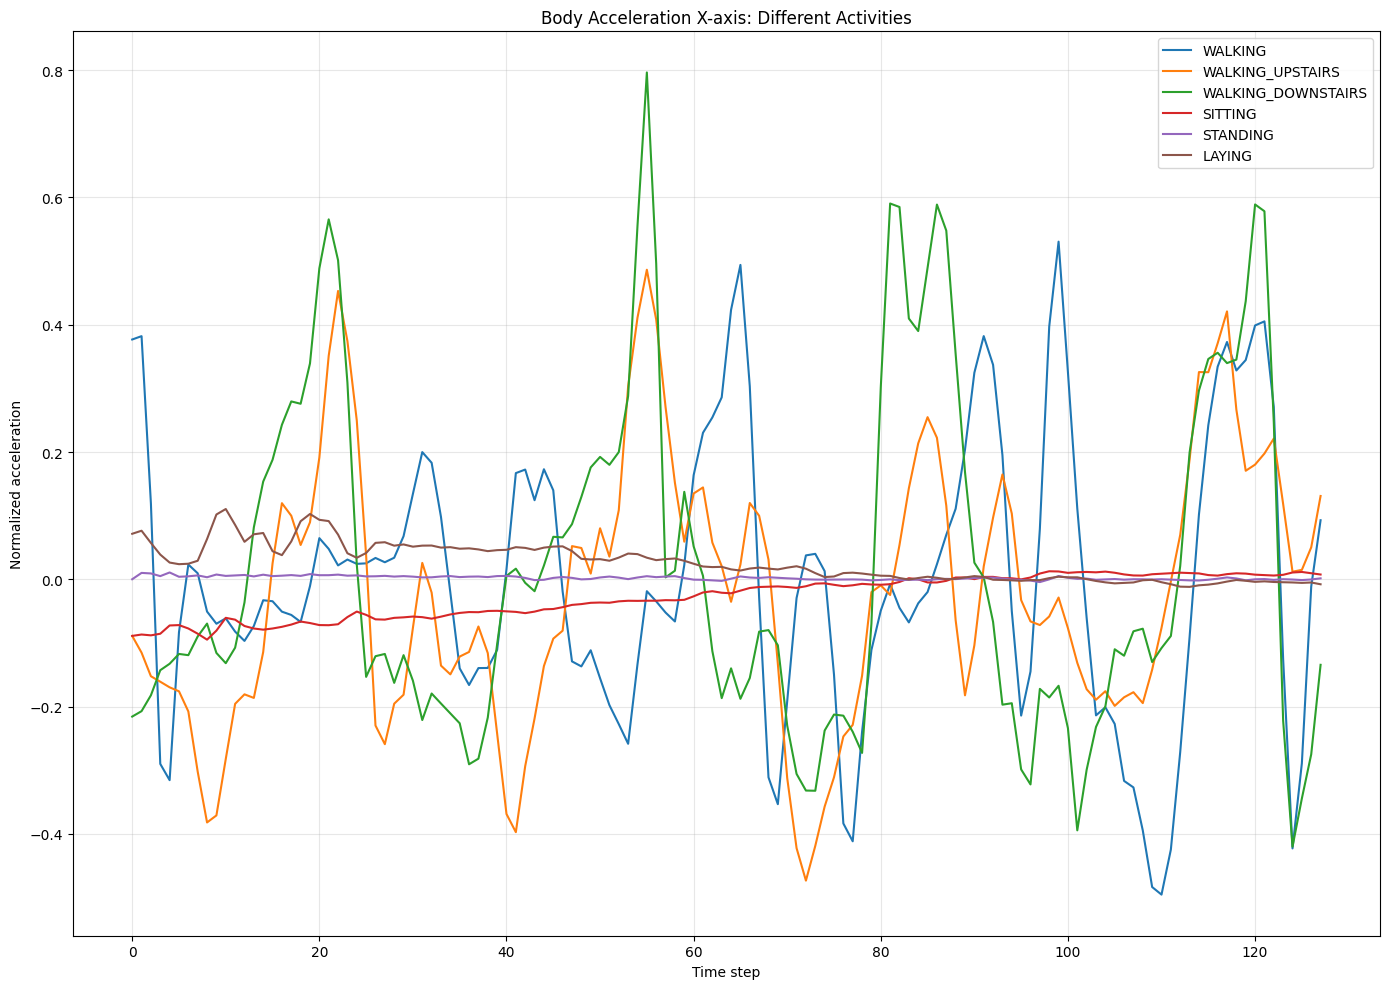

In [15]:
import numpy as np
import matplotlib.pyplot as plt

signal_path = (
    f"{dataset_path}/train/Inertial Signals/"
    "body_acc_x_train.txt"
)

body_acc_x = pd.read_csv(
    signal_path,
    sep=r"\s+",
    header=None
)

print("Signal shape:", body_acc_x.shape)

# Select one sample from each activity
activity_samples = {}

for activity_id in range(1, 7):
    index = np.where(y_train["activity_id"].values == activity_id)[0][0]
    activity_samples[activity_id] = index

# Plot the signals
plt.figure(figsize=(14, 10))

for activity_id, index in activity_samples.items():
    plt.plot(
        body_acc_x.iloc[index].values,
        label=label_map[activity_id]
    )

plt.title("Body Acceleration X-axis: Different Activities")
plt.xlabel("Time step")
plt.ylabel("Normalized acceleration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


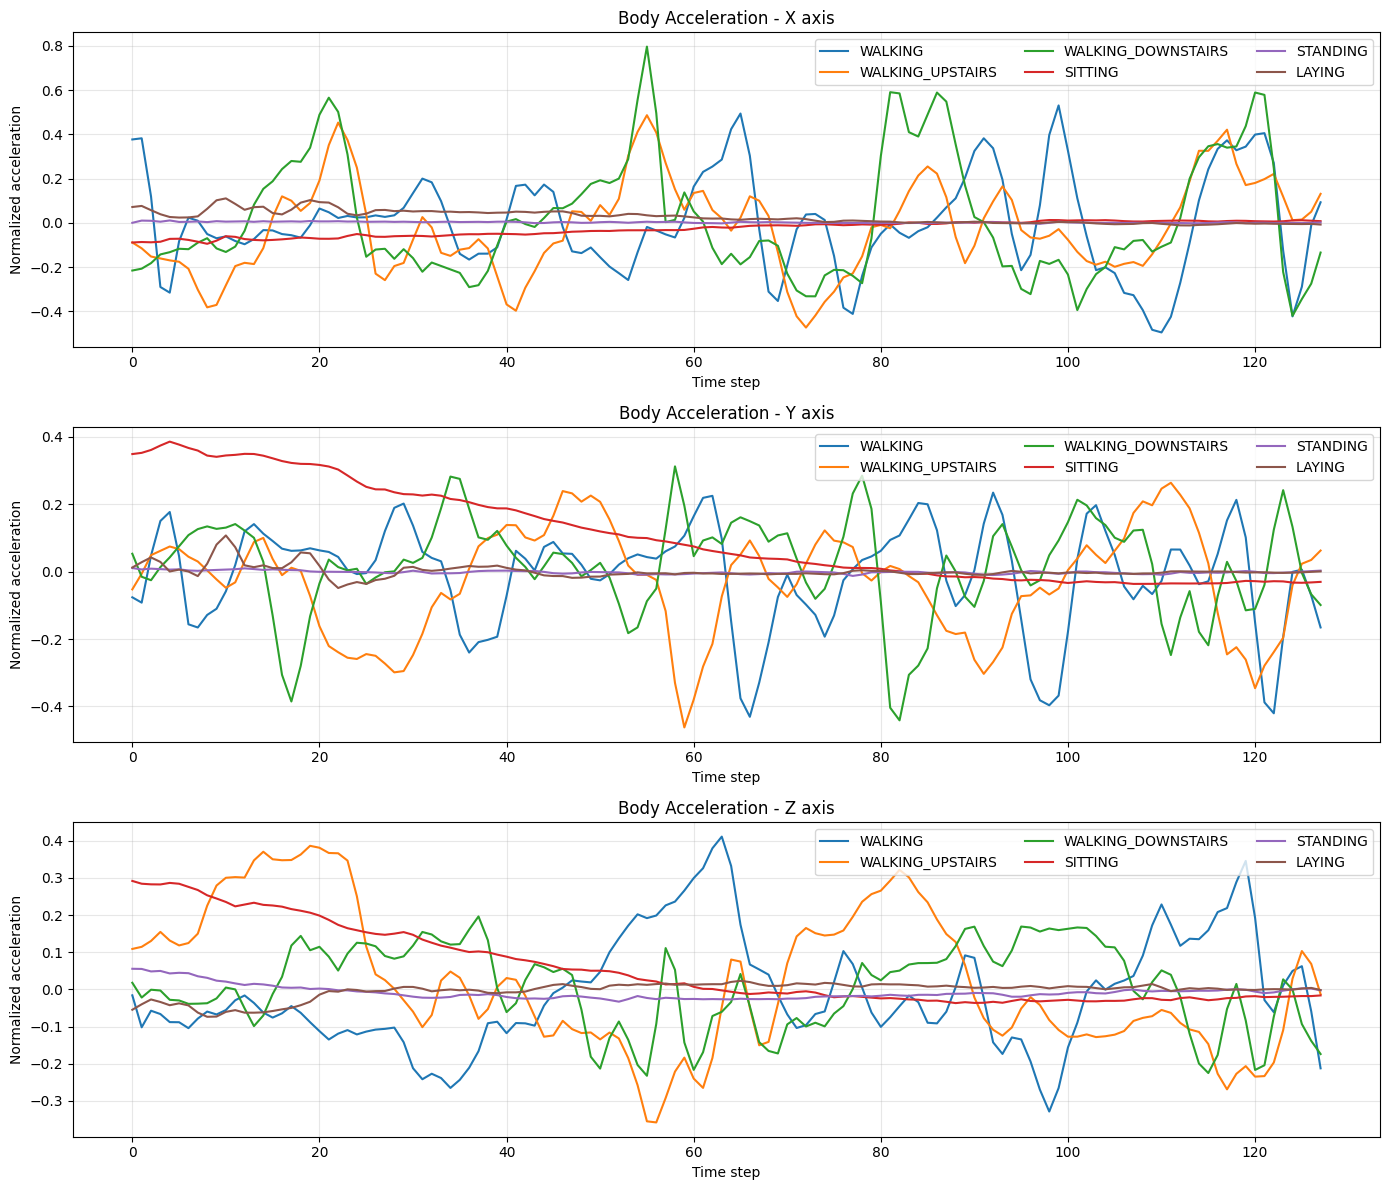

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

axes = ["x", "y", "z"]

fig, plots = plt.subplots(3, 1, figsize=(14, 12))

for i, axis in enumerate(axes):

    signal_path = (
        f"{dataset_path}/train/Inertial Signals/"
        f"body_acc_{axis}_train.txt"
    )

    signal_data = pd.read_csv(
        signal_path,
        sep=r"\s+",
        header=None
    )

    for activity_id, index in activity_samples.items():
        plots[i].plot(
            signal_data.iloc[index].values,
            label=label_map[activity_id]
        )

    plots[i].set_title(f"Body Acceleration - {axis.upper()} axis")
    plots[i].set_xlabel("Time step")
    plots[i].set_ylabel("Normalized acceleration")
    plots[i].grid(alpha=0.3)
    plots[i].legend(ncol=3)

plt.tight_layout()
plt.show()

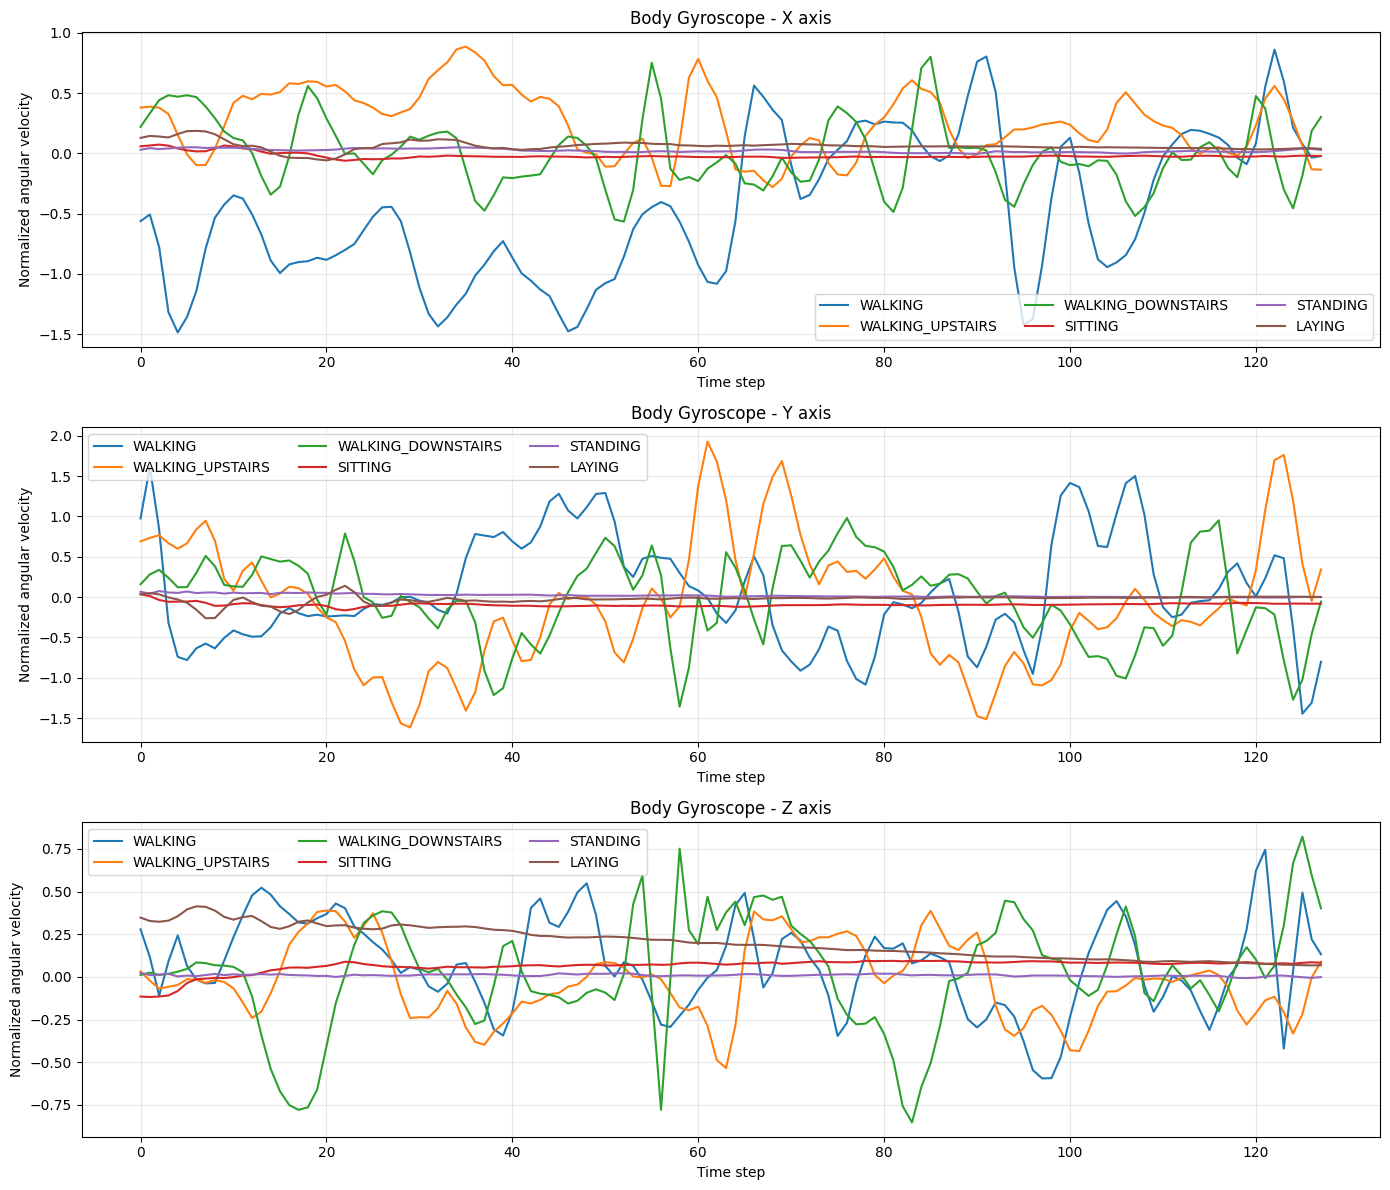

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

axes = ["x", "y", "z"]

fig, plots = plt.subplots(3, 1, figsize=(14, 12))

for i, axis in enumerate(axes):

    signal_path = (
        f"{dataset_path}/train/Inertial Signals/"
        f"body_gyro_{axis}_train.txt"
    )

    signal_data = pd.read_csv(
        signal_path,
        sep=r"\s+",
        header=None
    )

    for activity_id, index in activity_samples.items():
        plots[i].plot(
            signal_data.iloc[index].values,
            label=label_map[activity_id]
        )

    plots[i].set_title(f"Body Gyroscope - {axis.upper()} axis")
    plots[i].set_xlabel("Time step")
    plots[i].set_ylabel("Normalized angular velocity")
    plots[i].legend(ncol=3)
    plots[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# Statistical summary of the training feature matrix

print("FEATURE STATISTICS")
print("=" * 50)

print("\nDescriptive statistics:")
display(X_train.describe().round(4))

# Check features with zero variance
feature_std = X_train.std()

zero_variance = feature_std[feature_std == 0]

print("\nZero variance features:", len(zero_variance))

# Check feature value ranges
print("\nOverall minimum:", X_train.min().min())
print("Overall maximum:", X_train.max().max())

print("\nFeatures with lowest standard deviation:")
print(feature_std.nsmallest(10))

FEATURE STATISTICS

Descriptive statistics:


,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
count,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,...,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000,7352.0000
mean,0.2745,-0.0177,-0.1091,-0.6054,-0.5109,-0.6048,-0.6305,-0.5269,-0.6062,-0.4686,...,0.1253,-0.3070,-0.6253,0.0087,0.0022,0.0087,-0.0060,-0.4895,0.0586,-0.0565
std,0.0703,0.0408,0.0566,0.4487,0.5026,0.4187,0.4241,0.4859,0.4141,0.5445,...,0.2510,0.3210,0.3076,0.3368,0.4483,0.6083,0.4780,0.5118,0.2975,0.2791
min,-1.0000,-1.0000,-1.0000,-1.0000,-0.9999,-1.0000,-1.0000,-1.0000,-1.0000,-1.0000,...,-1.0000,-0.9954,-0.9998,-0.9766,-1.0000,-1.0000,-1.0000,-1.0000,-1.0000,-1.0000
25%,0.2630,-0.0249,-0.1210,-0.9928,-0.9781,-0.9802,-0.9936,-0.9782,-0.9803,-0.9362,...,-0.0237,-0.5426,-0.8456,-0.1215,-0.2895,-0.4823,-0.3763,-0.8121,-0.0179,-0.1434
50%,0.2772,-0.0172,-0.1087,-0.9462,-0.8519,-0.8594,-0.9507,-0.8573,-0.8571,-0.8816,...,0.1340,-0.3437,-0.7117,0.0095,0.0089,0.0087,-0.0004,-0.7094,0.1821,0.0032
75%,0.2885,-0.0108,-0.0978,-0.2428,-0.0342,-0.2624,-0.2927,-0.0667,-0.2657,-0.0171,...,0.2891,-0.1270,-0.5039,0.1509,0.2929,0.5062,0.3594,-0.5091,0.2484,0.1077
max,1.0000,1.0000,1.0000,1.0000,0.9162,1.0000,1.0000,0.9677,1.0000,1.0000,...,0.9467,0.9895,0.9568,1.0000,1.0000,0.9987,0.9961,1.0000,0.4782,1.0000



Zero variance features: 0

Overall minimum: -1.0
Overall maximum: 1.0

Features with lowest standard deviation:
1      0.040811
2      0.056635
388    0.058027
478    0.064748
492    0.065473
498    0.068311
0      0.070261
484    0.071548
501    0.071870
59     0.073333
dtype: float64


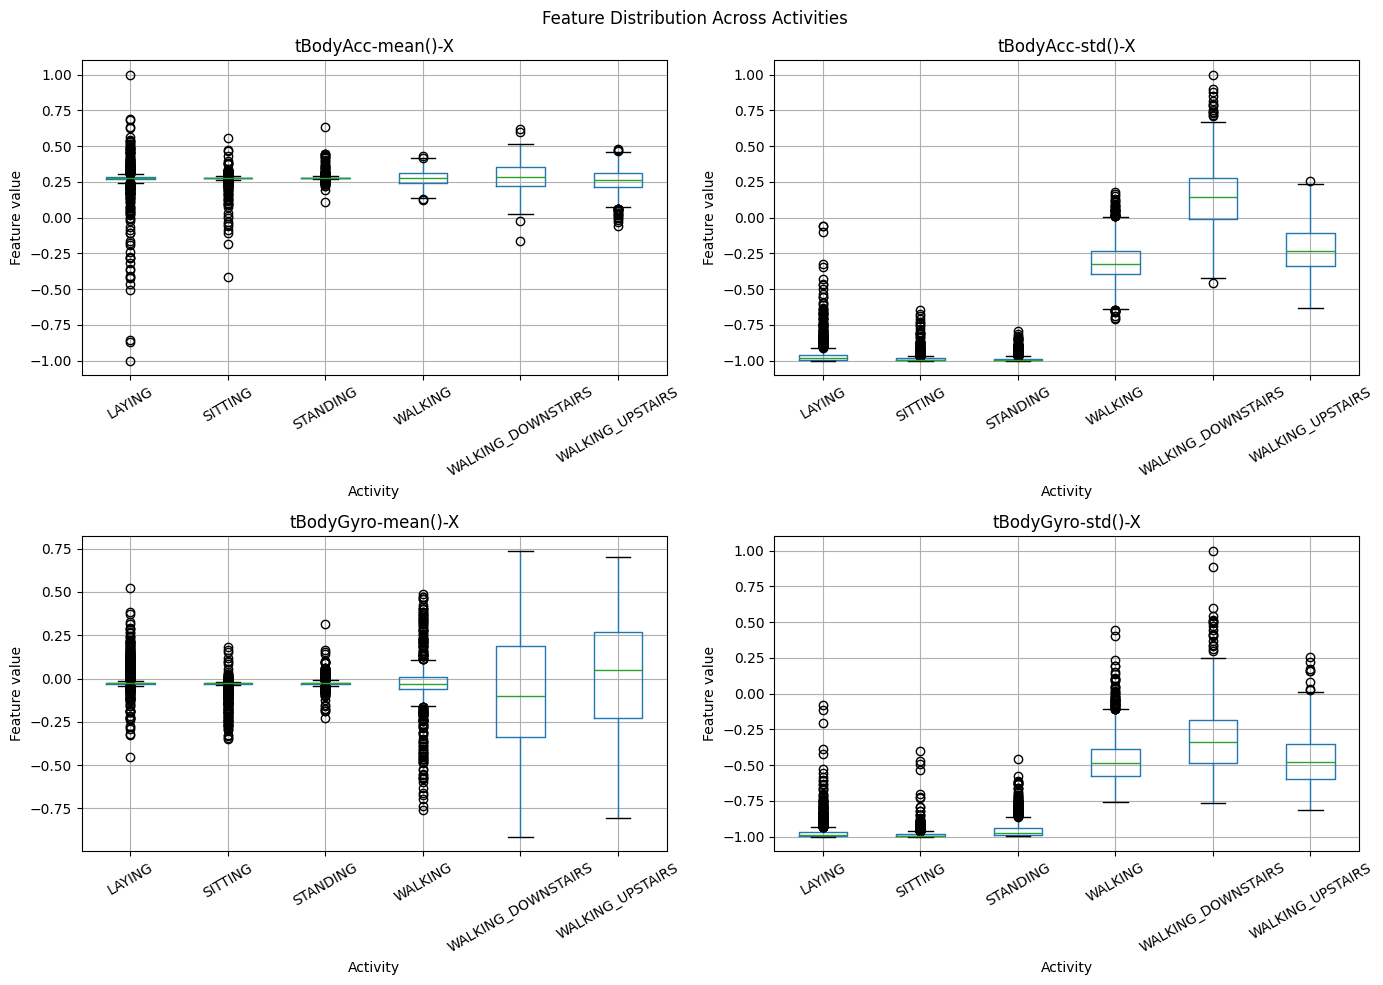

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

selected_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-std()-X",
    "tBodyGyro-mean()-X",
    "tBodyGyro-std()-X"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature_name in zip(axes.flat, selected_features):

    # Find the position of this feature
    position = features.index[
        features["feature_name"] == feature_name
    ][0]

    # Create a temporary dataframe
    plot_data = pd.DataFrame({
        "Activity": y_train["activity"],
        "Value": X_train.iloc[:, position]
    })

    # Compare feature values across activities
    plot_data.boxplot(
        column="Value",
        by="Activity",
        ax=ax,
        rot=30
    )

    ax.set_title(feature_name)
    ax.set_xlabel("Activity")
    ax.set_ylabel("Feature value")

plt.suptitle("Feature Distribution Across Activities")
plt.tight_layout()
plt.show()

In [20]:
X_test = pd.read_csv(
    f"{dataset_path}/test/X_test.txt",
    sep=r"\s+",
    header=None
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (7352, 561)
Testing: (2947, 561)


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train
print("Training Random Forest...")

rf_model.fit(X_train, y_train["activity_id"])

print("Training completed!")

# Predict
y_pred = rf_model.predict(X_test)

# Evaluate
accuracy = accuracy_score(y_test["activity_id"], y_pred)

print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test["activity_id"],
        y_pred,
        target_names=activity_labels["activity_name"].tolist()
    )
)

Training Random Forest...
Training completed!

Test Accuracy: 92.57%

Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.90      0.96      0.93       496
  WALKING_UPSTAIRS       0.89      0.91      0.90       471
WALKING_DOWNSTAIRS       0.96      0.85      0.90       420
           SITTING       0.92      0.89      0.90       491
          STANDING       0.90      0.92      0.91       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.93      0.93      2947



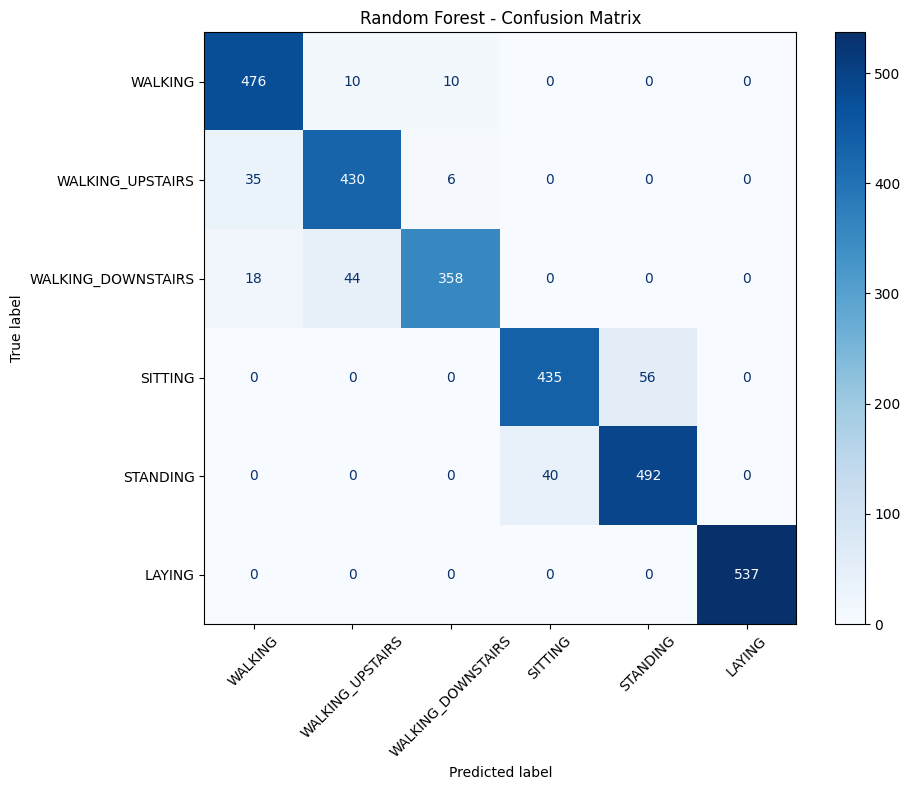

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test["activity_id"],
    y_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=activity_labels["activity_name"]
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

TOP 20 IMPORTANT FEATURES


,Feature_ID,Feature,Importance
40,41,tGravityAcc-mean()-X,0.041767
52,53,tGravityAcc-min()-X,0.031873
41,42,tGravityAcc-mean()-Y,0.029814
558,559,"angle(X,gravityMean)",0.026029
56,57,tGravityAcc-energy()-X,0.024059
559,560,"angle(Y,gravityMean)",0.023229
49,50,tGravityAcc-max()-X,0.022452
53,54,tGravityAcc-min()-Y,0.022102
50,51,tGravityAcc-max()-Y,0.019056
57,58,tGravityAcc-energy()-Y,0.016208


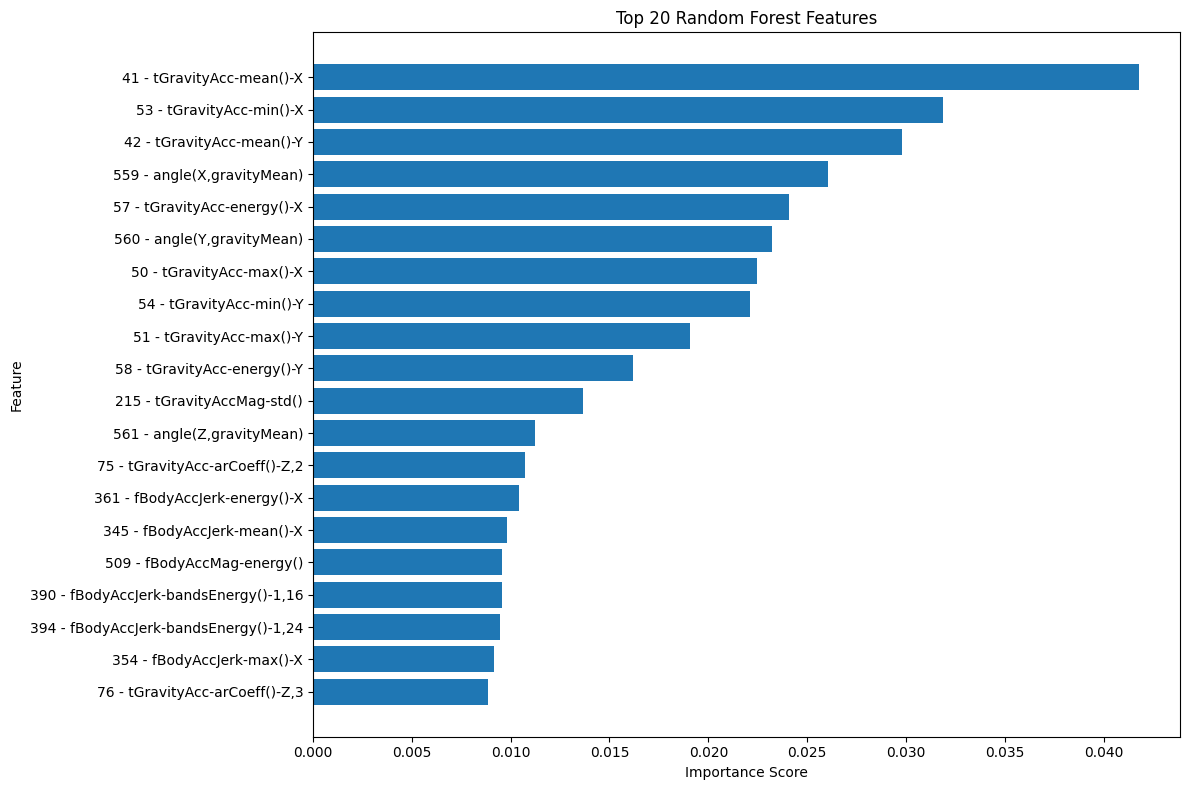

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as ipy_display

# Get feature importance scores
importance = rf_model.feature_importances_

# Create a dataframe
importance_df = pd.DataFrame({
    "Feature_ID": features["feature_id"],
    "Feature": features["feature_name"],
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20
print("TOP 20 IMPORTANT FEATURES")
ipy_display(importance_df.head(20))

# Visualize top 20
top_20 = importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_20["Feature_ID"].astype(str) + " - " + top_20["Feature"],
    top_20["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")
plt.tight_layout()
plt.show()